# Zero-Order Hold: Multiple Shooting

Solve the Cartesian two-body TOPS `P0` benchmark with multiple shooting, following the first example in [Zero-Order Hold I](./udp_zoh_point2point.ipynb). The interior states are initialized by propagating from the fixed endpoints.

In [1]:
import pykep as pk
import numpy as np
import pygmo as pg
import pygmo_plugins_nonfree as ppnf

from matplotlib import pyplot as plt

In [2]:
ipopt = pg.ipopt()
ipopt.set_integer_options({"max_iter": 2000})
ipopt.set_numeric_options({"tol": 1e-10})
ipopt.set_string_options({"sb": "yes"})

path_to_snopt72 = "/opt/lib/libsnopt7_c.so"
path_to_snopt72 = "/Users/dario.izzo/opt/lib/libsnopt7_c.dylib"
snopt = ppnf.snopt7(library=path_to_snopt72, minor_version=2, screen_output=False)
snopt.set_integer_option("Major iterations limit", 2000)
snopt.set_integer_option("Iterations limit", 20000)
snopt.set_numeric_option("Major optimality tolerance", 1e-3)
snopt.set_numeric_option("Major feasibility tolerance", 1e-12)
#snopt.set_integer_option("Hessian full memory", 1);


algo = pg.algorithm(snopt)

In [3]:
prob_name = "P4"
udp = pk.trajopt.gym.tops_twobody(prob_name, nseg=10, time_encoding="softmax", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Short arc transfer (GTOC style) - Fixed Time
Variables: 115 Equalities: 70 Inequalities: 10


Initialize the internal states of each population member from its controls and time grid. A propagated state outside the node bounds raises `ValueError`. A finite defect or a feasible fitness alone does not establish that every segment propagation succeeded.

In [4]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x, ballistic=False))

Compare the analytical gradient with finite differences. `prob.gradient_sparsity()` supplies the coordinates for either a sparse or dense gradient.

In [5]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-2.2872628180348187e-08, 2.6470715022708369e-08)

In [6]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final mass:", pop.champion_x[0] * udp.MASS)
print("Final tof:", pop.champion_x[4 * udp.nseg + 1] * udp.TIME)

Feasible: True
Objective: -0.599140027204
Final mass: 0.599140027204
Final tof: 2.0


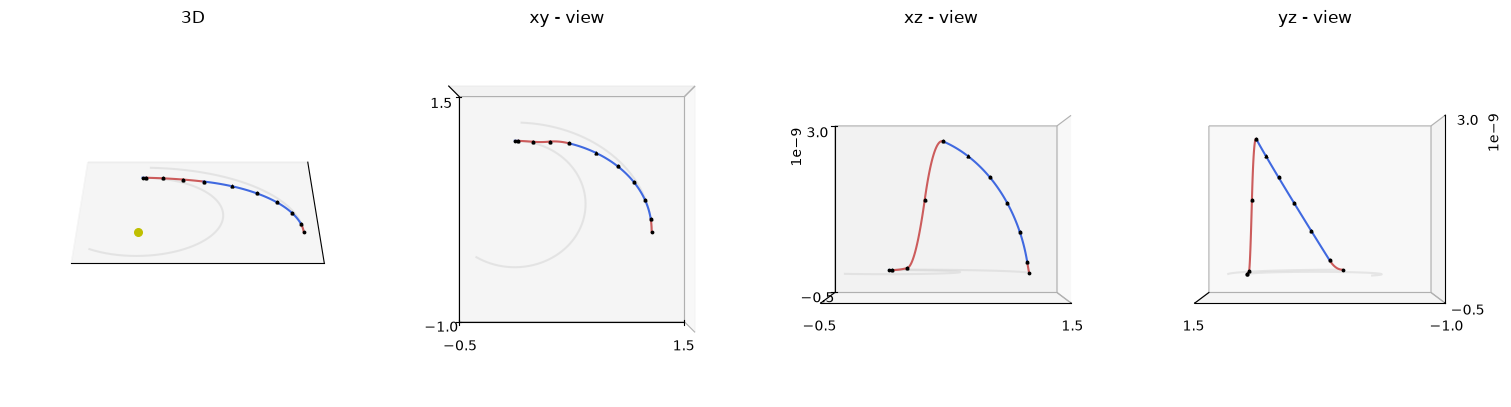

In [7]:
axes = udp.plot(pop.champion_x, N=100, mark_segments=True, s=3, c="k")

<Axes: xlabel='time grid', ylabel='throttle value (nd)'>

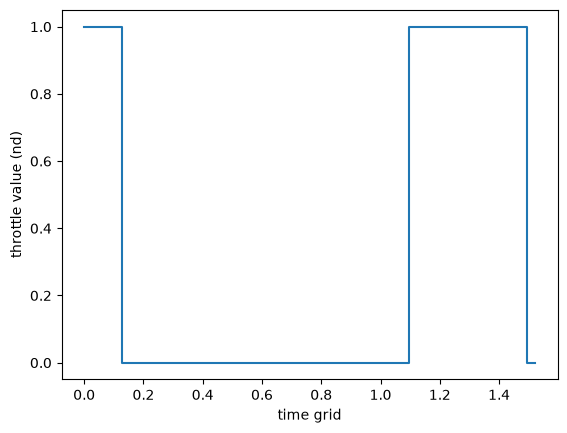

In [8]:
udp.plot_throttle(pop.champion_x)

# Two-body dynamics (Modified Equinoctial Elements)

This section solves the TOPS MEE `P0` benchmark with multiple shooting, following the corresponding single-shooting example in [Zero-Order Hold I](./udp_zoh_point2point.ipynb). As in the Cartesian example above, initialize the interior nodes before checking gradients or solving.

In [9]:
prob_name = "P0"
udp = pk.trajopt.gym.tops_mee(prob_name, nseg=10, time_encoding="softmax", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Dionysus problem (doi: 10.2514/1.G000379) - Fixed time
Variables: 115 Equalities: 70 Inequalities: 10


Initialize the interior nodes from the coast trajectory before evaluating the multiple-shooting fitness. The propagated nodes must remain within their MEE state bounds.

In [10]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x, ballistic=False))

Compare the sparse analytical gradient with finite differences, reconstructing the full Jacobian from pygmo's reported sparsity coordinates.

In [11]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-1.6145659212374319e-06, 1.0150261879147277e-06)

In [12]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final mass:", pop.champion_x[0] * udp.MASS)
print("Final tof:", pop.champion_x[4 * udp.nseg + 1] * udp.TIME)

Feasible: True
Objective: -0.629163222972
Final mass: 0.629163222972
Final tof: 60.7909197787


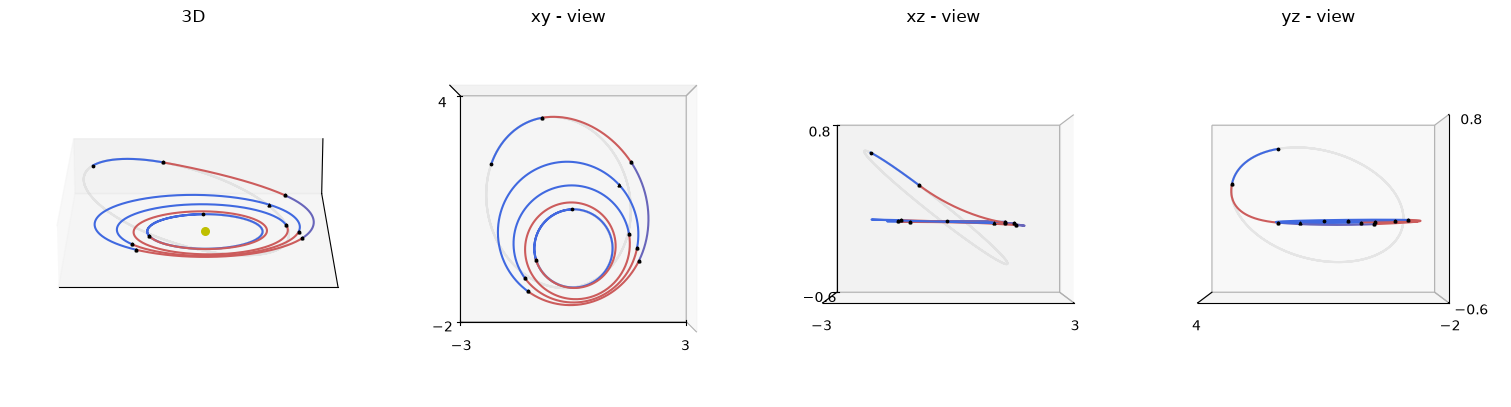

In [13]:
axes = udp.plot(pop.champion_x, N=300, mark_segments=True, s=3, c="k")

<Axes: xlabel='time grid', ylabel='throttle value (nd)'>

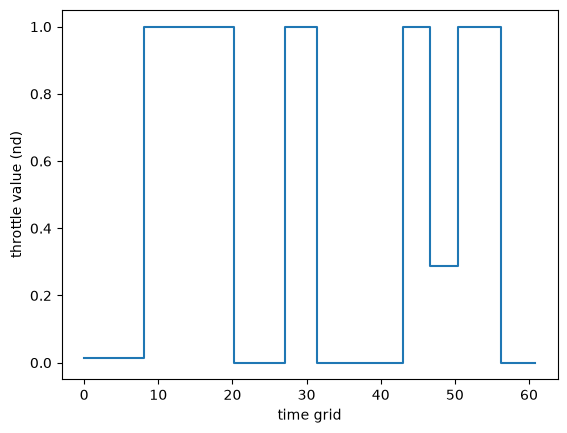

In [14]:
udp.plot_throttle(pop.champion_x)

# Circular Restricted Three-Body Problem (CR3BP)

This section solves the TOPS CR3BP `P0` benchmark with multiple shooting, following the corresponding single-shooting example in [Zero-Order Hold I](./udp_zoh_point2point.ipynb). The interior states are initialized before gradient checking and optimization.

In [15]:
prob_name = "P0"
udp = pk.trajopt.gym.tops_cr3bp(prob_name, nseg=20, time_encoding="softmax", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Halo 2 Halo in fixed tof
Variables: 235 Equalities: 160 Inequalities: 0


Initialize the interior nodes from the coast trajectory before evaluating the multiple-shooting fitness. Propagated nodes outside their bounds raise `ValueError`.

In [16]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x, ballistic=False))

Compare the sparse analytical gradient with finite differences, reconstructing the full Jacobian from pygmo's reported sparsity coordinates.

In [17]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-2.7337948571570792e-07, 2.3976052854202123e-07)

In [18]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final mass:", pop.champion_x[0])
print("Final tof:", pop.champion_x[4 * udp.nseg + 1])

Feasible: False
Objective: -0.979383503081
Final mass: 0.979383503081
Final tof: 5.0


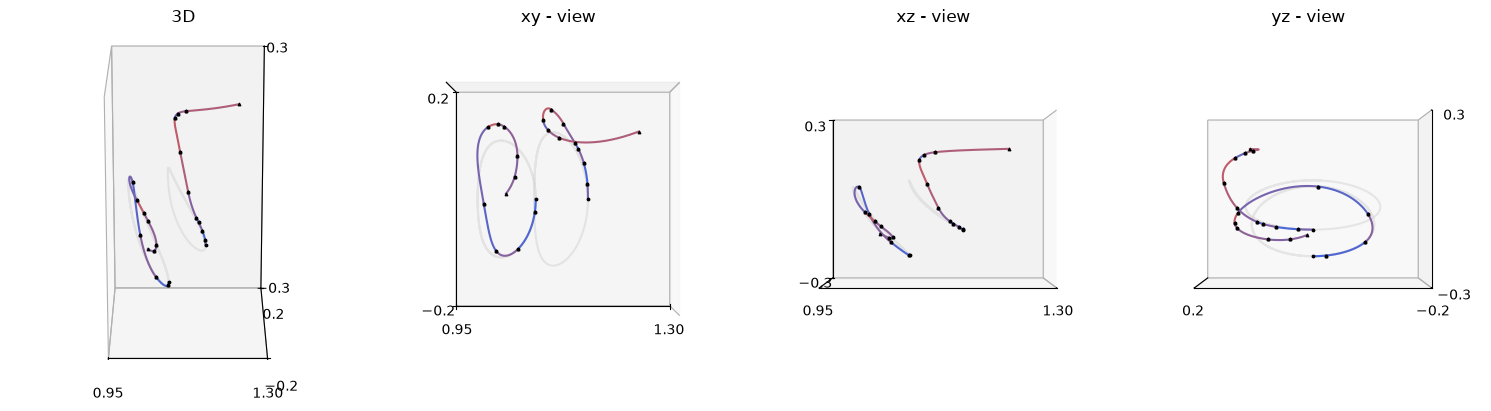

In [19]:
axes = udp.plot(pop.champion_x, N=1000, mark_segments=True, s=3, c="k")

<Axes: xlabel='time grid', ylabel='throttle value (nd)'>

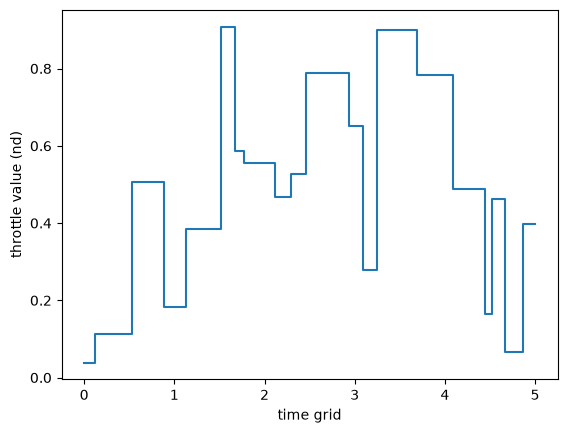

In [20]:
udp.plot_throttle(pop.champion_x)

# Solar-sail dynamics

This section solves a TOPS solar-sail benchmark with multiple shooting, using {class}`pykep.trajopt.gym.tops_ss` and `ms=True`. As in the other MS examples, initialize the interior states before checking gradients or solving. Solar-sail controls are the cone and clock angles; there are no throttle or mass variables.

In [21]:
# Load a TOPS solar-sail benchmark using multiple shooting
prob_name = "P1"
udp = pk.trajopt.gym.tops_ss(prob_name, nseg=10, time_encoding="uniform", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Eccentric (e=0.5, a=2) to highly-eccentric (e=0.9, a=10) orbit at periapsis (rp=1, nd)
Variables: 75 Equalities: 60 Inequalities: 0


Initialize the interior states from the sail trajectory before checking gradients or solving. The guessed states are subject to the configured six-dimensional node bounds.

In [22]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x, ballistic=False))

Compare the sparse analytical gradient with finite differences, reconstructing the full Jacobian from pygmo's reported sparsity coordinates.

In [23]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-1.2969877261070906e-06, 1.4632194941244236e-06)

In [24]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final tof:", pop.champion_x[2 * udp.nseg] * udp.TIME)

Feasible: True
Objective: 180.0
Final tof: 180.0


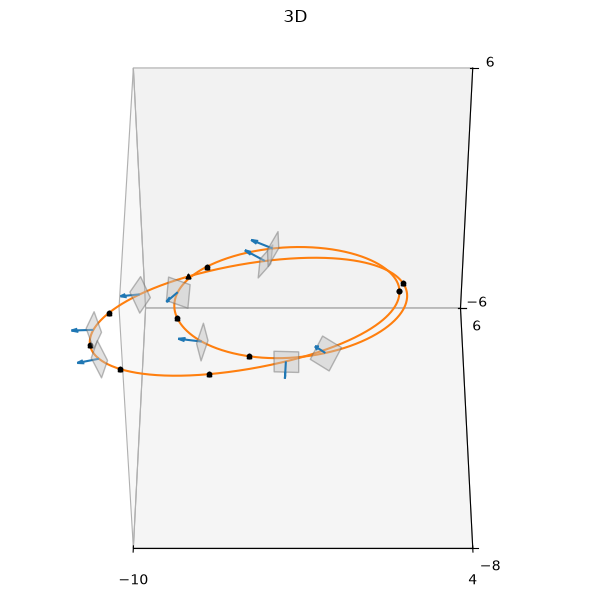

In [25]:
axes = udp.plot(pop.champion_x, N=300, mark_segments=True, sail_size=0.5, s=10, c="k")